# ПР-10. Кластеризация: сегменты абонентов

Данные `o_churn_synthetic.csv` из ПР-8 и ПР-9: 3000 абонентов. **Датасет синтетический, это не данные реального оператора.**

Задача без учителя: разбить абонентов на сегменты по поведению. Разметку `churn` (ушёл абонент или нет) намеренно скрываю: в кластеризации она не участвует. В конце использую её только для проверки, получились ли осмысленные сегменты.

Для кластеризации беру 9 числовых признаков поведения. `region` и `tariff` не беру: категории плохо сочетаются с евклидовым расстоянием K-Means, а `subscriber_code` это идентификатор.

Вариант B: число кластеров по методу локтя и силуэту, профили и названия кластеров, проверка устойчивости.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

DATA_PATH = "../data/o_churn_synthetic.csv"
SEED = 42

df = pd.read_csv(DATA_PATH)
FEATURES = ["tenure_months", "monthly_charge_som", "internet_gb", "support_calls_3m",
            "autopay", "days_since_topup", "topups_3m", "dropped_calls_pct", "balance_som"]
hidden_churn = df["churn"]          # разметка скрыта: в кластеризации не участвует
X = df[FEATURES]
print(df.shape, "| признаков для кластеризации:", len(FEATURES))
print("scikit-learn", sklearn.__version__)

(3000, 13) | признаков для кластеризации: 9
scikit-learn 1.9.1


## Веха 10.1. Зачем масштабировать признаки

K-Means относит точку к ближайшему центру по евклидову расстоянию. Посмотрим, в каких единицах признаки:

In [2]:
X.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
tenure_months,27.60,19.54,0.0,120.00
monthly_charge_som,467.55,190.05,150.0,859.00
internet_gb,16.12,12.72,0.2,117.80
support_calls_3m,1.16,1.10,0.0,7.00
autopay,0.35,0.48,0.0,1.00
days_since_topup,11.87,11.77,0.0,90.00
topups_3m,7.68,1.67,0.0,12.00
dropped_calls_pct,2.22,1.09,0.0,6.83
balance_som,80.33,47.25,0.0,226.00


Разброс отличается в сотни раз: `monthly_charge_som` около 190 сомов, а `autopay` и `support_calls_3m` около 1. Проверю, что будет, если кластеризовать без масштабирования: насколько центры кластеров расходятся по каждому признаку.

In [3]:
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

# Что будет без масштабирования: какой признак определяет кластеры
raw = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X)
spread = pd.DataFrame(raw.cluster_centers_, columns=FEATURES).std().sort_values(ascending=False)
print("Разброс центров кластеров БЕЗ масштабирования (в единицах признаков):")
print(spread.round(2).to_string())

Разброс центров кластеров БЕЗ масштабирования (в единицах признаков):
monthly_charge_som    213.68
internet_gb             6.68
balance_som             3.45
tenure_months           0.55
days_since_topup        0.32
dropped_calls_pct       0.06
support_calls_3m        0.04
autopay                 0.03
topups_3m               0.03


**Вывод.** Без масштабирования кластеры отличаются почти только по `monthly_charge_som` (центры расходятся на 214 сомов) и немного по `internet_gb`. По остальным семи признакам центры практически одинаковые: K-Means просто нарезал абонентов по сумме платежа, потому что этот признак даёт самые большие расстояния. Дальше все признаки привожу к среднему 0 и стандартному отклонению 1 через `StandardScaler`, тогда каждый признак весит одинаково.

## Веха 10.2. Число кластеров: метод локтя и силуэт

Для k от 2 до 10 обучаю K-Means (`n_init=10`, `random_state=42`) и считаю:

- **инерцию**: сумму квадратов расстояний от точек до центра своего кластера (чем меньше, тем плотнее кластеры, но она всегда падает с ростом k);
- **коэффициент силуэта**: для каждой точки (b − a) / max(a, b), где a это среднее расстояние до своего кластера, b до ближайшего чужого. От −1 до 1, чем больше, тем лучше кластеры отделены.

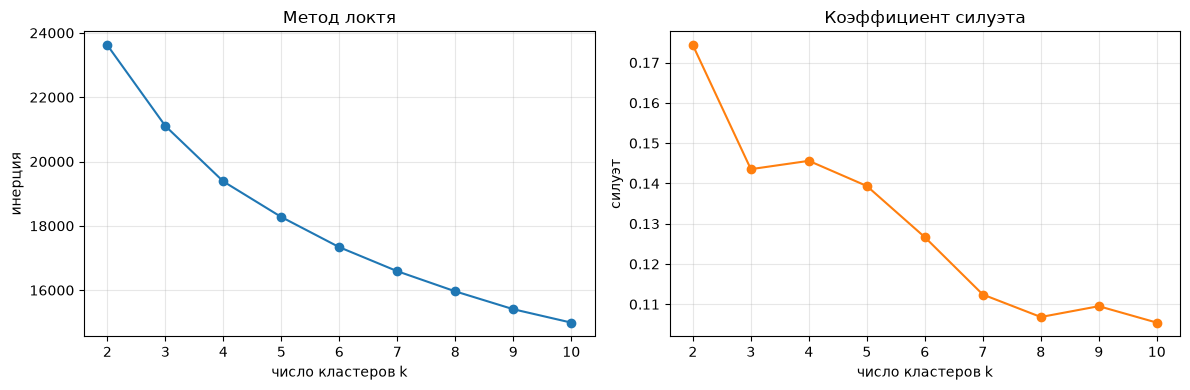

,инерция,силуэт,"снижение инерции, %"
k,,,
2,23617.228,0.174,NaN
3,21105.149,0.144,10.637
4,19379.767,0.146,8.175
5,18273.960,0.139,5.706
6,17335.576,0.127,5.135
7,16588.583,0.112,4.309
8,15962.001,0.107,3.777
9,15406.944,0.110,3.477
10,14990.247,0.105,2.705


In [4]:
ks = range(2, 11)
rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
    rows.append({"k": k, "инерция": km.inertia_,
                 "силуэт": silhouette_score(Xs, km.labels_, random_state=SEED)})
scores = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(scores.index, scores["инерция"], "o-")
axes[0].set(title="Метод локтя", xlabel="число кластеров k", ylabel="инерция")
axes[1].plot(scores.index, scores["силуэт"], "o-", color="C1")
axes[1].set(title="Коэффициент силуэта", xlabel="число кластеров k", ylabel="силуэт")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
scores.assign(**{"снижение инерции, %": (-scores["инерция"].pct_change() * 100)}).round(3)

**Что показывают критерии.**

- **Метод локтя.** Резкого излома нет, кривая гладкая. Но видно, где отдача падает: переход 2 → 3 снижает инерцию на 10,6%, 3 → 4 на 8,2%, а дальше каждый новый кластер даёт уже 5,7%, 5,1% и меньше. Локоть, насколько он вообще есть, на k = 4.
- **Силуэт** максимален при k = 2 (0,174), падает при k = 3 (0,144) и снова чуть растёт при k = 4 (0,146), после чего только убывает. То есть k = 4 лучше соседей по силуэту, хотя хуже k = 2.
- Все значения силуэта низкие (0,10–0,17): у абонентов нет чётко разделённых групп, сегменты перекрываются. Это нормально для поведенческих данных: люди не делятся на типы резко.

**Выбор: k = 4.** Критерии указывают на разные k, это ожидаемо (подсказка в задании). k = 2 даёт лучший силуэт, но два сегмента почти бесполезны для бизнеса. k = 4 это локоть по инерции и локальный максимум силуэта, а дальше (веха 10.3) у каждого из четырёх кластеров есть понятный смысл. При k = 6 и больше разбиение ещё и неустойчиво (веха 10.4).

## Веха 10.3. Профили кластеров

Средние значения исходных признаков в каждом кластере:

In [5]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Xs)
labels = km.labels_
profile = X.assign(cluster=labels).groupby("cluster").mean()
profile.insert(0, "абонентов", pd.Series(labels).value_counts().sort_index())
profile.round(2)

,абонентов,tenure_months,monthly_charge_som,internet_gb,support_calls_3m,autopay,days_since_topup,topups_3m,dropped_calls_pct,balance_som
cluster,,,,,,,,,,
0,837,27.57,439.57,13.16,1.15,1.00,8.22,8.11,2.23,82.41
1,403,27.96,453.02,14.37,1.11,0.26,34.36,4.84,2.18,82.77
2,1339,27.12,414.67,11.77,1.14,0.00,7.77,8.23,2.20,80.27
3,421,28.85,705.29,37.47,1.29,0.23,10.64,7.77,2.31,74.07


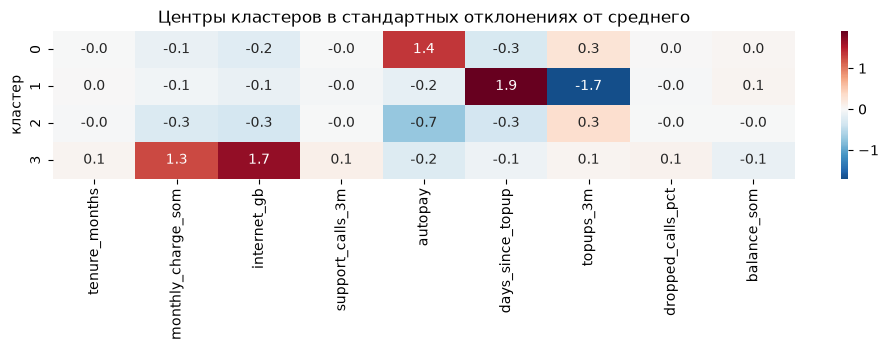

In [6]:
# Те же профили в стандартизованных единицах: насколько кластер выше (+) или ниже (-) среднего
z = pd.DataFrame(km.cluster_centers_, columns=FEATURES)
plt.figure(figsize=(10, 3.6))
sns.heatmap(z, annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Центры кластеров в стандартных отклонениях от среднего")
plt.ylabel("кластер")
plt.tight_layout()
plt.show()

По тепловой карте видно, чем каждый кластер отличается от среднего абонента. Сильнее всего различаются `autopay`, `days_since_topup`, `topups_3m`, `internet_gb` и `monthly_charge_som`. По `support_calls_3m`, `dropped_calls_pct`, `tenure_months` и `balance_som` кластеры почти одинаковые (центры в пределах ±0,15 стандартного отклонения), эти признаки сегменты не определяют.

Названия кластеров по их профилю:

- **0, «автоплатёж»** (837 абонентов): у всех включён автоплатёж (`autopay` = 1,00), пополняют регулярно (8 раз за 3 месяца), последнее пополнение 8 дней назад, тариф и интернет средние.
- **1, «редко пополняют»** (403): последнее пополнение 34 дня назад (среднее по базе 12), всего 4,8 пополнения за 3 месяца, автоплатёж у четверти. Абоненты, которые фактически перестают пользоваться номером.
- **2, «ручная оплата»** (1339, самый большой): автоплатежа нет ни у кого, но пополняют сами так же регулярно, как кластер 0; самые дешёвые тарифы (415 сомов) и меньше всех интернета (11,8 ГБ).
- **3, «много интернета»** (421): 37,5 ГБ интернета (в 3 раза больше среднего) и самый дорогой платёж (705 сомов).

In [7]:
NAMES = {0: "автоплатёж", 1: "редко пополняют", 2: "ручная оплата", 3: "много интернета"}
profile.assign(сегмент=[NAMES[c] for c in profile.index])[["сегмент", "абонентов", "monthly_charge_som",
    "internet_gb", "autopay", "days_since_topup", "topups_3m"]].round(2)

,сегмент,абонентов,monthly_charge_som,internet_gb,autopay,days_since_topup,topups_3m
cluster,,,,,,,
0,автоплатёж,837,439.57,13.16,1.00,8.22,8.11
1,редко пополняют,403,453.02,14.37,0.26,34.36,4.84
2,ручная оплата,1339,414.67,11.77,0.00,7.77,8.23
3,много интернета,421,705.29,37.47,0.23,10.64,7.77


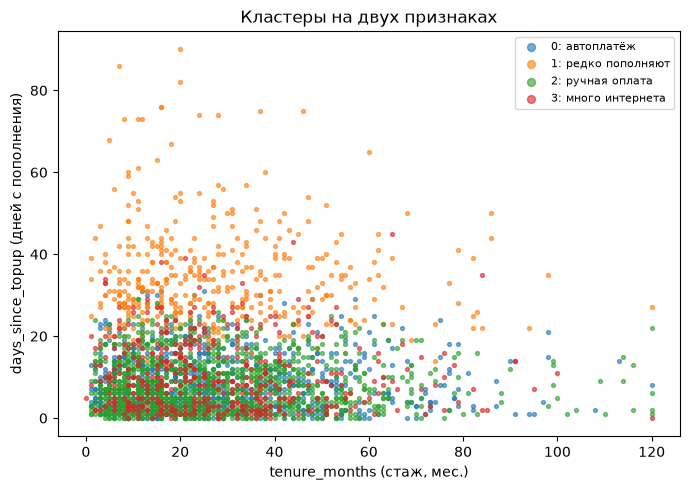

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
for c in range(K):
    m = labels == c
    ax.scatter(X.loc[m, "tenure_months"], X.loc[m, "days_since_topup"], s=8, alpha=0.6,
               label=f"{c}: {NAMES.get(c, c)}")
ax.set(xlabel="tenure_months (стаж, мес.)", ylabel="days_since_topup (дней с пополнения)",
       title="Кластеры на двух признаках")
ax.legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()

На двух признаках видно, что кластер «редко пополняют» отделяется по `days_since_topup` (верхняя часть графика). Остальные три кластера на этих осях перемешаны: они различаются по другим признакам (`autopay`, `internet_gb`), которые здесь не нарисованы. Это и есть причина низкого силуэта: 9-мерные сегменты на двух осях не разделить.

## Веха 10.4. Устойчивость

Повторяю кластеризацию с другими `random_state` и сравниваю разбиения через ARI (adjusted Rand index): 1 означает те же группы (номера кластеров могут быть переставлены, ARI это не волнует), 0 значит совпадение не лучше случайного.

In [9]:
base = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(Xs)
rows = []
for rs in [0, 1, 7, 123, 2026]:
    other = KMeans(n_clusters=K, n_init=10, random_state=rs).fit_predict(Xs)
    one = KMeans(n_clusters=K, n_init=1, random_state=rs).fit_predict(Xs)
    rows.append({"random_state": rs,
                 "ARI с базовым (n_init=10)": adjusted_rand_score(base, other),
                 "ARI с базовым (n_init=1)": adjusted_rand_score(base, one)})
pd.DataFrame(rows).set_index("random_state").round(3)

,ARI с базовым (n_init=10),ARI с базовым (n_init=1)
random_state,,
0,0.996,0.988
1,0.994,0.618
7,0.995,0.995
123,0.987,0.988
2026,0.987,0.562


**Вывод.** С `n_init=10` (K-Means 10 раз стартует со случайных центров и оставляет лучший результат) разбиение на 4 кластера почти не зависит от `random_state`: ARI 0,987–0,996, то есть меняют кластер единицы абонентов на границах. С одним запуском (`n_init=1`) результат зависит от начальных центров: при `random_state` = 1 и 2026 ARI всего 0,62 и 0,56, K-Means застрял в другом локальном минимуме. Поэтому `n_init` больше 1 обязателен.

Проверю устойчивость и для соседних k:

In [10]:
# Устойчивость при других k: насколько совпадают разбиения при разных random_state
rows = []
for k in [2, 3, 4, 5, 6]:
    parts = [KMeans(n_clusters=k, n_init=10, random_state=rs).fit_predict(Xs) for rs in [0, 1, 7, 123, 2026]]
    aris = [adjusted_rand_score(parts[i], parts[j]) for i in range(5) for j in range(i + 1, 5)]
    rows.append({"k": k, "ARI среднее": np.mean(aris), "ARI минимум": np.min(aris)})
pd.DataFrame(rows).set_index("k").round(3)

,ARI среднее,ARI минимум
k,,
2,0.992,0.986
3,1.000,1.000
4,0.994,0.990
5,0.992,0.987
6,0.736,0.584


При k от 2 до 5 разбиения устойчивы (ARI не ниже 0,986). При k = 6 разные запуски дают разные группы (ARI в среднем 0,74, в худшем случае 0,58): шестой кластер выделяется случайно, у данных нет такой структуры. Это ещё один довод против большого k.

## Веха 10.5. Проверка по скрытой разметке

Теперь открываю `churn`, который в кластеризации не участвовал, и смотрю долю ушедших в каждом сегменте.

In [11]:
check = pd.DataFrame({"cluster": labels, "churn": hidden_churn})
by_cluster = check.groupby("cluster")["churn"].agg(["size", "mean"]).rename(
    columns={"size": "абонентов", "mean": "доля ушедших"})
by_cluster["сегмент"] = [NAMES.get(c, c) for c in by_cluster.index]
print(f"доля ушедших во всей базе: {hidden_churn.mean():.3f}")
by_cluster.round(3)

доля ушедших во всей базе: 0.371


,абонентов,доля ушедших,сегмент
cluster,,,
0,837,0.223,автоплатёж
1,403,0.583,редко пополняют
2,1339,0.406,ручная оплата
3,421,0.354,много интернета


**Вывод.** Сегменты осмысленные: доля ушедших в них сильно разная, хотя K-Means про отток ничего не знал.

- **«Редко пополняют»**: ушли 58,3%, в 1,6 раза больше, чем в среднем по базе (37,1%). Давно не пополняют и почти не пользуются: это абоненты, которые уже уходят.
- **«Автоплатёж»**: ушли 22,3%, меньше всех. Абоненту с автоплатежом не нужно каждый раз решать «пополнить или нет», поэтому он реже уходит.
- **«Ручная оплата»** (40,6%) и **«много интернета»** (35,4%) близки к среднему.

Практический смысл: оператору стоит работать с сегментом «редко пополняют» (напоминания, бонус за пополнение) и предлагать автоплатёж «ручной оплате». Кластеризация здесь не заменяет модель оттока из ПР-8, но даёт понятные группы для разных действий.

## Итог

| k | Инерция | Силуэт | ARI между запусками (среднее) |
| --- | --- | --- | --- |
| 2 | 23617 | 0,174 | 0,992 |
| 3 | 21105 | 0,144 | 1,000 |
| **4** | **19380** | **0,146** | **0,994** |
| 5 | 18274 | 0,139 | 0,992 |
| 6 | 17336 | 0,127 | 0,736 |

- Признаки обязательно масштабировать: без этого K-Means делит абонентов только по сумме платежа.
- Метод локтя и силуэт указали на разные k (локоть около 4, максимум силуэта при 2). Выбрал **k = 4**: локоть по инерции, локальный максимум силуэта, устойчивость (ARI 0,99) и четыре понятных сегмента. При k ≥ 6 разбиение неустойчиво.
- Сегменты: «автоплатёж», «редко пополняют», «ручная оплата», «много интернета». Названия даны по характерным значениям признаков.
- Силуэт низкий (0,15): сегменты перекрываются, жёстких групп у абонентов нет.
- Проверка по скрытому `churn` показала, что сегменты осмысленные: от 22,3% ушедших у «автоплатежа» до 58,3% у «редко пополняют».